# Day 76: Project 1 — Sales Prediction: Problem + EDA

## Objective
- Download and explore the Rossmann Store Sales data
- Define the problem clearly: what is X, what is y, what metric to optimize
- EDA: structure, missing values, sales distribution, sales over time
- Find patterns before modeling: day of week, month, top stores, promotions

> **Data:** the real Rossmann Store Sales data from Kaggle (`train.csv`, `store.csv`).
> The files are not included in this repo (competition data rules). The notebook reads them from `data/` if you
> have them there, otherwise it downloads them from a public copy. See `data/README.md`.

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter

## 1. The problem (written before touching the data)

**Business question:** Rossmann store managers need to predict each store's **daily sales** up to **6 weeks ahead**,
so they can plan staff, stock, and promotions.

| | |
|---|---|
| **Problem type** | Supervised **regression**, and the rows are ordered in time |
| **Target (y)** | `Sales`: turnover of one store on one day |
| **Features (X)** | store, day of week, date parts, `Promo`, `StateHoliday`, `SchoolHoliday`, and store details from `store.csv` (type, assortment, competition) |
| **NOT allowed as a feature** | `Customers`. It is very informative, but we will not know tomorrow's customers when we forecast |
| **Metric** | **RMSPE** (root mean squared *percentage* error), the Kaggle metric. It measures relative error, so a 500 error on a 5,000-sale day counts like a 1,000 error on a 10,000-sale day |
| **Validation** | **Time-based**: train on the past, validate on the last 42 days (6 weeks). No random split, because that would leak the future |

$$\text{RMSPE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(\frac{y_i - \hat{y}_i}{y_i}\right)^2}$$

Days with `Sales = 0` (closed stores) are left out of the score, because the percentage error is undefined there.

## 2. Load the data

In [2]:
BASE = "https://raw.githubusercontent.com/RPI-DATA/tutorials-intro/master/rossmann-store-sales/rossmann-store-sales/"

def load(name):
    local = Path("data") / name
    return pd.read_csv(local if local.exists() else BASE + name, low_memory=False)

train = load("train.csv")
store = load("store.csv")

train["Date"] = pd.to_datetime(train["Date"])
train = train.sort_values(["Store", "Date"]).reset_index(drop=True)

In [3]:
print("train:", train.shape, "| store:", store.shape)
print("Dates:", train["Date"].min().date(), "to", train["Date"].max().date())
print("Stores:", train["Store"].nunique())
print("Days covered:", train["Date"].nunique())

train: (1017209, 9) | store: (1115, 10)
Dates: 2013-01-01 to 2015-07-31
Stores: 1115
Days covered: 942


In [4]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   Store          1017209 non-null  int64         
 1   DayOfWeek      1017209 non-null  int64         
 2   Date           1017209 non-null  datetime64[us]
 3   Sales          1017209 non-null  int64         
 4   Customers      1017209 non-null  int64         
 5   Open           1017209 non-null  int64         
 6   Promo          1017209 non-null  int64         
 7   StateHoliday   1017209 non-null  str           
 8   SchoolHoliday  1017209 non-null  int64         
dtypes: datetime64[us](1), int64(7), str(1)
memory usage: 69.8 MB


In [5]:
train.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,2,2013-01-01,0,0,0,0,a,1
1,1,3,2013-01-02,5530,668,1,0,0,1
2,1,4,2013-01-03,4327,578,1,0,0,1
3,1,5,2013-01-04,4486,619,1,0,0,1
4,1,6,2013-01-05,4997,635,1,0,0,1


## 3. Missing values (%)

In [6]:
print("train: any missing values?", bool(train.isna().any().any()))
print()
print("store.csv, % missing:")
miss = (store.isna().mean() * 100).round(1)
print(miss[miss > 0])

train: any missing values? False

store.csv, % missing:
CompetitionDistance           0.3
CompetitionOpenSinceMonth    31.7
CompetitionOpenSinceYear     31.7
Promo2SinceWeek              48.8
Promo2SinceYear              48.8
PromoInterval                48.8
dtype: float64


## 4. Closed days and zero sales

In [7]:
closed = (train["Open"] == 0).mean() * 100
print("Rows where the store is closed:", round(closed, 1), "%")
print("Rows with Sales = 0:", int((train["Sales"] == 0).sum()))
print("  ...of which the store was OPEN:", int(((train["Sales"] == 0) & (train["Open"] == 1)).sum()))
print("Closed rows with Sales > 0:", int(((train["Open"] == 0) & (train["Sales"] > 0)).sum()))

Rows where the store is closed: 17.0 %
Rows with Sales = 0: 172871


  ...of which the store was OPEN: 54
Closed rows with Sales > 0: 0


Closed days always have zero sales, so they would drag any average down.
From here on, "open days" means `Open == 1` and `Sales > 0`.

In [8]:
open_days = train[(train["Open"] == 1) & (train["Sales"] > 0)].copy()
open_days["Month"] = open_days["Date"].dt.month
print("Open days:", len(open_days))

Open days: 844338


## 5. Sales distribution

count    844338.0
mean       6956.0
std        3104.0
min          46.0
25%        4859.0
50%        6369.0
75%        8360.0
max       41551.0
Name: Sales, dtype: float64
Skew: 1.59


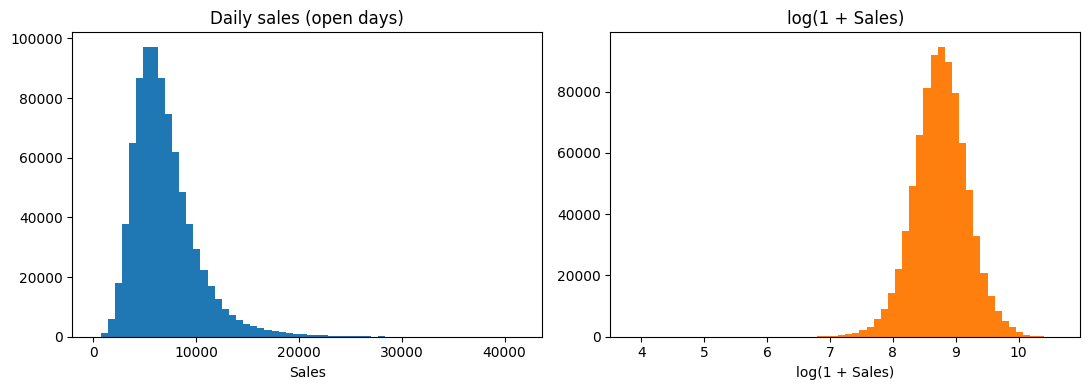

In [9]:
print(open_days["Sales"].describe().round(0))
print("Skew:", round(open_days["Sales"].skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(open_days["Sales"], bins=60, color="#1f77b4")
ax[0].set_title("Daily sales (open days)")
ax[0].set_xlabel("Sales")
ax[1].hist(np.log1p(open_days["Sales"]), bins=60, color="#ff7f0e")
ax[1].set_title("log(1 + Sales)")
ax[1].set_xlabel("log(1 + Sales)")
plt.tight_layout()
plt.savefig("images/sales_distribution.png", dpi=150)
plt.show()

## 6. Sales over time

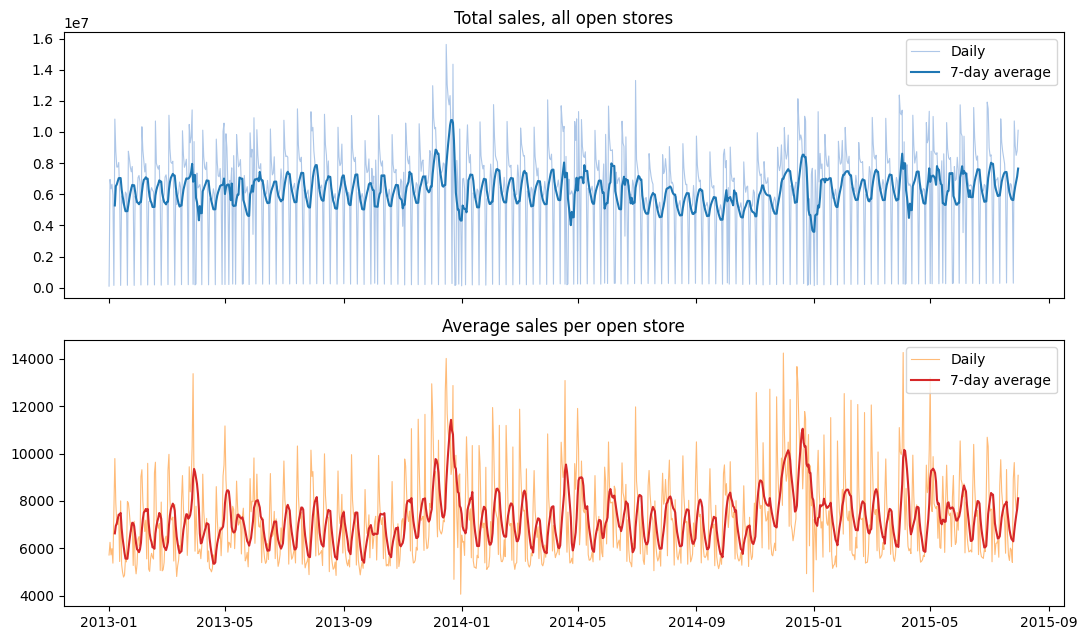

In [10]:
daily = open_days.groupby("Date").agg(total=("Sales", "sum"), per_store=("Sales", "mean"), stores_open=("Store", "nunique"))

fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
ax[0].plot(daily.index, daily["total"], color="#aec7e8", linewidth=0.8, label="Daily")
ax[0].plot(daily.index, daily["total"].rolling(7).mean(), color="#1f77b4", label="7-day average")
ax[0].set_title("Total sales, all open stores")
ax[0].legend()
ax[1].plot(daily.index, daily["per_store"], color="#ffbb78", linewidth=0.8, label="Daily")
ax[1].plot(daily.index, daily["per_store"].rolling(7).mean(), color="#d62728", label="7-day average")
ax[1].set_title("Average sales per open store")
ax[1].legend()
plt.tight_layout()
plt.savefig("images/sales_trend_over_time.png", dpi=150)
plt.show()

## 7. Patterns: day of week, month, top stores, promotions

       mean   count
Mon  8216.0  137557
Tue  7088.0  143955
Wed  6729.0  141922
Thu  6768.0  134626
Fri  7073.0  138633
Sat  5875.0  144052
Sun  8225.0    3593


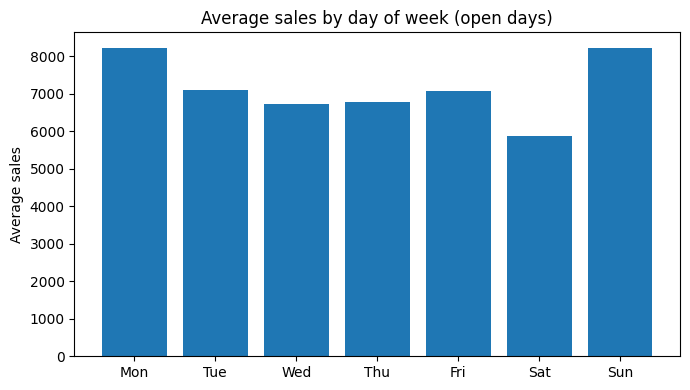

In [11]:
by_dow = open_days.groupby("DayOfWeek")["Sales"].agg(["mean", "count"]).round(0)
by_dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print(by_dow)

plt.figure(figsize=(7, 4))
plt.bar(by_dow.index, by_dow["mean"], color="#1f77b4")
plt.title("Average sales by day of week (open days)")
plt.ylabel("Average sales")
plt.tight_layout()
plt.savefig("images/sales_by_day_of_week.png", dpi=150)
plt.show()

{1: 6564.0, 2: 6589.0, 3: 6977.0, 4: 7047.0, 5: 7107.0, 6: 7001.0, 7: 6954.0, 8: 6649.0, 9: 6547.0, 10: 6603.0, 11: 7189.0, 12: 8609.0}


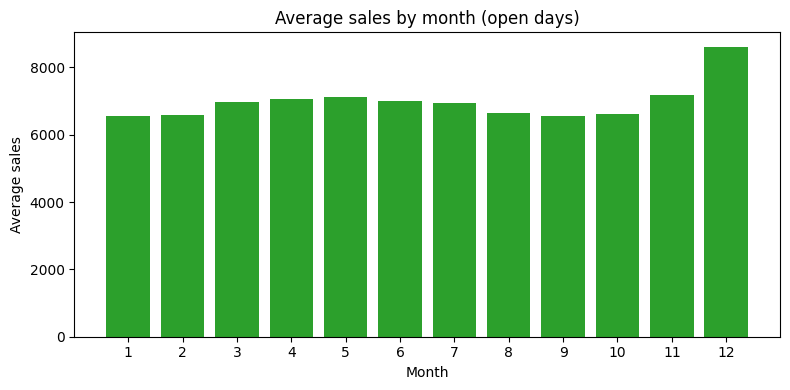

In [12]:
by_month = open_days.groupby("Month")["Sales"].mean().round(0)
print(by_month.to_dict())

plt.figure(figsize=(8, 4))
plt.bar(by_month.index, by_month.values, color="#2ca02c")
plt.xticks(range(1, 13))
plt.xlabel("Month")
plt.ylabel("Average sales")
plt.title("Average sales by month (open days)")
plt.tight_layout()
plt.savefig("images/sales_by_month.png", dpi=150)
plt.show()

Store
817     21757.0
262     20719.0
1114    20667.0
251     19123.0
842     18575.0
513     18179.0
562     17970.0
788     17962.0
383     17295.0
756     16575.0
Name: Sales, dtype: float64
Average store: 6935 | Best store: 817


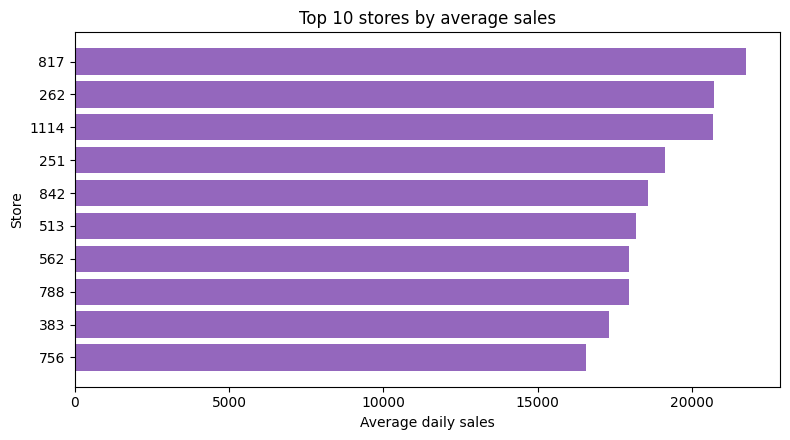

In [13]:
top10 = open_days.groupby("Store")["Sales"].mean().sort_values(ascending=False).head(10).round(0)
print(top10)
print("Average store:", round(open_days.groupby("Store")["Sales"].mean().mean()), "| Best store:", int(top10.index[0]))

plt.figure(figsize=(8, 4.5))
plt.barh(top10.index.astype(str)[::-1], top10.values[::-1], color="#9467bd")
plt.xlabel("Average daily sales")
plt.ylabel("Store")
plt.title("Top 10 stores by average sales")
plt.tight_layout()
plt.savefig("images/top10_stores_avg_sales.png", dpi=150)
plt.show()

In [14]:
# Promotions and holidays (open days only)
print("Average sales by Promo:")
print(open_days.groupby("Promo")["Sales"].mean().round(0))
promo = open_days.groupby("Promo")["Sales"].mean()
print("Promo uplift:", round((promo[1] / promo[0] - 1) * 100, 1), "%")
print()
print("Average sales by StateHoliday ('0' = none):")
print(open_days.groupby("StateHoliday")["Sales"].agg(["mean", "count"]).round(0))

Average sales by Promo:
Promo
0    5930.0
1    8229.0
Name: Sales, dtype: float64
Promo uplift: 38.8 %

Average sales by StateHoliday ('0' = none):
                mean   count
StateHoliday                
0             6954.0  843428
a             8487.0     694
b             9888.0     145
c             9744.0      71


## 8. Customers: strong signal, but a leak

In [15]:
corr = open_days[["Sales", "Customers"]].corr().iloc[0, 1]
print("Correlation Sales vs Customers:", round(corr, 2))
print("Sales per customer (median):", round((open_days["Sales"] / open_days["Customers"]).median(), 1))

Correlation Sales vs Customers: 0.82
Sales per customer (median): 9.2


`Customers` is tightly linked to `Sales`, but we would not know it when forecasting 6 weeks ahead, so it stays out of X.

## 9. Stores with missing days

In [16]:
all_dates = pd.date_range(train["Date"].min(), train["Date"].max())
days_per_store = train.groupby("Store")["Date"].nunique()
gappy = days_per_store[days_per_store < len(all_dates)].index
print("Days in the full period:", len(all_dates))
print("Stores with missing days:", len(gappy))

windows = Counter()
for s in gappy:
    missing = all_dates.difference(train.loc[train["Store"] == s, "Date"])
    windows[(missing.min().date(), missing.max().date(), len(missing))] += 1
for (start, end, n), stores in windows.most_common(3):
    print(stores, "stores missing", n, "days between", start, "and", end)

Days in the full period: 942
Stores with missing days: 181


180 stores missing 184 days between 2014-07-01 and 2014-12-31
1 stores missing 1 days between 2013-01-01 and 2013-01-01


Total sales dipped in the second half of 2014. Was it weaker demand, or fewer stores?

In [17]:
h2 = train[train["Date"].between("2014-07-01", "2014-12-31")]
print("Stores with no rows from 2014-07-01 to 2014-12-31:", 1115 - h2["Store"].nunique())

for y in (2013, 2014):
    m = (daily.index >= f"{y}-07-01") & (daily.index <= f"{y}-12-31")
    print(y, "| stores open per day:", round(daily.loc[m, "stores_open"].mean()),
          "| sales per open store:", round(daily.loc[m, "per_store"].mean()),
          "| total per day:", round(daily.loc[m, "total"].mean()))

Stores with no rows from 2014-07-01 to 2014-12-31: 180
2013 | stores open per day: 937 | sales per open store: 7202 | total per day: 6524372
2014 | stores open per day: 787 | sales per open store: 7520 | total per day: 5662078


## 10. Baselines (the numbers any model must beat)

In [18]:
def rmspe(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    mask = y_true > 0
    return np.sqrt(np.mean(((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2))

# Validation = the last 42 days (6 weeks), like the real forecasting task
cut = train["Date"].max() - pd.Timedelta(days=41)
past = open_days[open_days["Date"] < cut]
valid = open_days[open_days["Date"] >= cut].copy()
print("Validation starts:", cut.date(), "| validation rows:", len(valid))

Validation starts: 2015-06-20 | validation rows: 40282


In [19]:
# 1) One number for everyone
valid["p1"] = past["Sales"].mean()

# 2) Each store's own average
valid["p2"] = valid["Store"].map(past.groupby("Store")["Sales"].mean()).fillna(past["Sales"].mean())

# 3) Store + day of week
g3 = past.groupby(["Store", "DayOfWeek"])["Sales"].mean().rename("p3")
valid = valid.join(g3, on=["Store", "DayOfWeek"])
valid["p3"] = valid["p3"].fillna(valid["p2"])

# 4) Store + day of week + promo
g4 = past.groupby(["Store", "DayOfWeek", "Promo"])["Sales"].mean().rename("p4")
valid = valid.join(g4, on=["Store", "DayOfWeek", "Promo"])
valid["p4"] = valid["p4"].fillna(valid["p3"])

for label, col in [("1) global average", "p1"), ("2) store average", "p2"),
                   ("3) store + day of week", "p3"), ("4) store + day + promo", "p4")]:
    print(f"{label:26s} RMSPE = {rmspe(valid['Sales'], valid[col]):.3f}")

1) global average          RMSPE = 0.583
2) store average           RMSPE = 0.331
3) store + day of week     RMSPE = 0.236
4) store + day + promo     RMSPE = 0.147


## Practice Exercise
Which store type (`StoreType` a, b, c, d) has the highest average sales, and how many stores are in each?

In [20]:
by_type = open_days.merge(store[["Store", "StoreType"]], on="Store").groupby("StoreType")["Sales"].mean().round(0)
count_type = store["StoreType"].value_counts().sort_index()
print(pd.DataFrame({"avg_sales": by_type, "stores": count_type}))

           avg_sales  stores
StoreType                   
a             6926.0     602
b            10233.0      17
c             6933.0     148
d             6822.0     348


## Mini Challenge
Does the promo effect depend on the day of week? Compare average sales with and without promo for each weekday.

In [21]:
tbl = open_days.groupby(["DayOfWeek", "Promo"])["Sales"].mean().unstack().round(0)
tbl["uplift_%"] = ((tbl[1] / tbl[0] - 1) * 100).round(1)
tbl.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print(tbl)

Promo       0       1  uplift_%
Mon    6223.0  9773.0      57.0
Tue    5716.0  8278.0      44.8
Wed    5618.0  7686.0      36.8
Thu    5751.0  7599.0      32.1
Fri    6344.0  7744.0      22.1
Sat    5875.0     NaN       NaN
Sun    8225.0     NaN       NaN


## EDA findings so far
- Closed days (about 17% of rows) have zero sales, so they must be handled separately
- Sales are right-skewed, a few very big days and stores pull the average up
- Weekday pattern is strong, and promotions lift sales a lot
- December is the strongest month
- A group of stores has missing days (see section 9)
- `Customers` is a leak, we must not use it
- Simple baselines already give a benchmark RMSPE for the models in the next days

## Summary
- The problem: predict daily sales per store 6 weeks ahead, scored with RMSPE on a time-based validation set
- EDA found strong day-of-week, month, promo, and store effects
- Baselines set the bar for tomorrow's feature engineering and modeling
- Next: Day 77, feature engineering (date features, lags, encodings)